# Trening modelu przewidującego czas półmaratonu

Notebook wczytuje wyniki z DigitalOcean Spaces, przygotowuje dane, porównuje modele regresyjne, zapisuje najlepszy model i przesyła go z powrotem do Spaces. Wymaga zmiennych `DO_SPACES_*` w pliku `.env`.

## 1. Połączenie z magazynem danych

In [ ]:
import os
from io import BytesIO

import boto3
import pandas as pd
from botocore.client import Config
from dotenv import load_dotenv

# fra1

load_dotenv() # wczytanie zmiennych środowiskowych z pliku .env do środowiska Pythona

REGION = os.environ["DO_SPACES_REGION"]
BUCKET = os.environ["DO_SPACES_BUCKET"]

s3 = boto3.client(
    "s3",
    region_name=REGION,
    endpoint_url=os.environ["DO_SPACES_ENDPOINT"],
    aws_access_key_id=os.environ["DO_SPACES_KEY"],
    aws_secret_access_key=os.environ["DO_SPACES_SECRET"],
    # config=Config(signature_version="s3v4"),
)

In [ ]:
# Funkcja do wczytywania plików CSV z DigitalOcean Spaces

def read_csv_from_spaces(key):
    obj = s3.get_object(Bucket=BUCKET, Key=key)
    return pd.read_csv(
        BytesIO(obj["Body"].read()),
        sep=";"
    )

# Wczytanie danych dla roku 2023
df_2023 = read_csv_from_spaces(
    "data/halfmarathon_wroclaw_2023__final.csv"
)

df_2023.head()

,Miejsce,Numer startowy,Imię,Nazwisko,Miasto,Kraj,Drużyna,Płeć,Płeć Miejsce,Kategoria wiekowa,...,10 km Tempo,15 km Czas,15 km Miejsce Open,15 km Tempo,20 km Czas,20 km Miejsce Open,20 km Tempo,Tempo Stabilność,Czas,Tempo
0,1.0,1787,TOMASZ,GRYCKO,NaN,POL,UKS BLIZA WŁADYSŁAWOWO,M,1.0,M30,...,2.926667,00:44:47,1.0,3.106667,01:01:43,1.0,3.386667,0.031400,01:04:59,3.080509
1,2.0,3,ARKADIUSZ,GARDZIELEWSKI,WROCŁAW,POL,ARKADIUSZGARDZIELEWSKI.PL,M,2.0,M30,...,2.983333,00:45:26,2.0,3.143333,01:03:08,2.0,3.540000,0.038000,01:06:23,3.146875
2,3.0,3832,KRZYSZTOF,HADAS,POZNAŃ,POL,NaN,M,3.0,M20,...,3.123333,00:47:34,3.0,3.236667,01:05:09,3.0,3.516667,0.024067,01:08:24,3.242475
3,4.0,416,DAMIAN,DYDUCH,KĘPNO,POL,AZS POLITECHNIKA OPOLSKA,M,4.0,M30,...,3.196667,00:48:49,5.0,3.330000,01:06:54,4.0,3.616667,0.025467,01:10:16,3.330963
4,5.0,8476,KAMIL,MAŃKOWSKI,MIRKÓW,POL,PARKRUN WROCŁAW,M,5.0,M20,...,3.276667,00:49:31,7.0,3.386667,01:07:27,5.0,3.586667,0.023000,01:10:27,3.339654


In [4]:
# Wczytanie danych dla roku 2024

df_2024 = read_csv_from_spaces(
    "data/halfmarathon_wroclaw_2024__final.csv"
)

df_2024.head()

,Miejsce,Numer startowy,Imię,Nazwisko,Miasto,Kraj,Drużyna,Płeć,Płeć Miejsce,Kategoria wiekowa,...,10 km Tempo,15 km Czas,15 km Miejsce Open,15 km Tempo,20 km Czas,20 km Miejsce Open,20 km Tempo,Tempo Stabilność,Czas,Tempo
0,1.0,596,NIKODEM,DWORCZAK,KOŚCIAN,POL,NaN,M,1.0,M20,...,2.920000,00:45:07,2.0,3.083333,01:00:33,1.0,3.086667,0.007267,01:04:03,3.036265
1,2.0,616,MATEUSZ,KACZOR,RADOM,POL,RLTL OPTIMA RADOM,M,2.0,M20,...,2.920000,00:45:07,3.0,3.083333,01:00:38,2.0,3.103333,0.008267,01:04:24,3.052856
2,3.0,154,PATRYK,KOZŁOWSKI,RADOM,POL,RLTL-ZTE-RADOM,M,3.0,M20,...,2.920000,00:45:07,1.0,3.083333,01:00:59,3.0,3.173333,0.012467,01:04:40,3.065497
3,4.0,591,DARIUSZ,BORATYŃSKI,WROCŁAW,POL,WOSIEK TEAM AZS AWF WROCŁAW,M,4.0,M20,...,3.110000,00:47:48,4.0,3.293333,01:05:40,4.0,3.573333,0.028667,01:09:44,3.305681
4,5.0,521,SZYMON,DOROŻYŃSKI,LUBON,POL,SZYMI TEAM AZS POLITECHNIKA OPOLSKA,M,5.0,M30,...,3.153333,00:48:09,5.0,3.453333,01:06:05,5.0,3.586667,0.039800,01:10:05,3.322272


In [5]:
print("2023:", df_2023.shape)
print("2024:", df_2024.shape)

2023: (8950, 27)
2024: (13007, 27)


## 2. Połączenie wyników i przygotowanie cech

In [6]:
# dodanie kolumny z rokiem wydarzenia do obu DataFrame'ów

df_2023["event_year"] = 2023
df_2024["event_year"] = 2024

In [7]:
# Połączenie danych z obu lat w jeden DataFrame

df = pd.concat(
    [df_2023, df_2024],
    ignore_index=True
)

df.shape

(21957, 28)

In [8]:
# Wybór istotnych kolumn do dalszej analizy

data = df[ ["Płeć", "Rocznik", "5 km Czas", "Czas", "event_year"] ].copy()
data.head()

,Płeć,Rocznik,5 km Czas,Czas,event_year
0,M,1992.0,00:14:37,01:04:59,2023
1,M,1986.0,00:14:48,01:06:23,2023
2,M,1996.0,00:15:46,01:08:24,2023
3,M,1988.0,00:16:11,01:10:16,2023
4,M,1995.0,00:16:12,01:10:27,2023


In [10]:
# Sprawdzenie ilości brakujących wartości w wybranych kolumnach
data.isna().sum()

Płeć            11
Rocznik        485
5 km Czas     3546
Czas          2055
event_year       0
dtype: int64

In [11]:
print("Przed usunięciem braków:", data.shape)

data = data.dropna(
    subset=["Płeć", "Rocznik", "5 km Czas", "Czas"]
).copy()

print("Po usunięciu braków:", data.shape)

Przed usunięciem braków: (21957, 5)
Po usunięciu braków: (17927, 5)


In [27]:
# Obliczenie wieku uczestników na podstawie roku wydarzenia i rocznika

data["age"] = (
    data["event_year"] - pd.to_numeric(data["Rocznik"], errors="coerce")
)

data.loc[:, ["Rocznik", "event_year", "age"]].head()
# data['age'].describe()

,Rocznik,event_year,age
0,1992.0,2023,31.0
1,1986.0,2023,37.0
2,1996.0,2023,27.0
3,1988.0,2023,35.0
4,1995.0,2023,28.0


In [16]:
# Wyświetlenie uczestników o nietypowym wieku (młodszych niż 16 lat lub starszych niż 100 lat)

data.loc[
    (data["age"] < 16) | (data["age"] > 100),
    ["Rocznik", "event_year", "age", "Płeć", "5 km Czas", "Czas"]
].shape

(18, 6)

In [28]:
import numpy as np
# Ustawienie wieku uczestników na NaN, jeśli jest nietypowy (młodszy niż 16 lat lub starszy niż 100 lat)

data.loc[
    (data["age"] < 16) | (data["age"] > 100),
    "age"
] = np.nan

data['age'].describe()

count    17909.000000
mean        39.181529
std         10.231956
min         17.000000
25%         32.000000
50%         39.000000
75%         46.000000
max         89.000000
Name: age, dtype: float64

In [34]:
model_columns = ["Płeć", "age", "5 km Czas", "Czas"]
# print(data.loc[:, model_columns].shape)
# data.loc[:, model_columns].dropna().shape
# print(data.loc[:, model_columns].shape)

model_data = data.loc[:, model_columns].dropna().copy()
model_data.shape

(17909, 4)

In [35]:
model_data["time_5k_seconds"] = (
    pd.to_timedelta(model_data["5 km Czas"], errors="coerce").dt.total_seconds()
)

model_data["halfmarathon_seconds"] = (
    pd.to_timedelta(model_data["Czas"], errors="coerce").dt.total_seconds()
)

In [37]:
model_data[
    ["age", "time_5k_seconds", "halfmarathon_seconds"]
].describe()

,age,time_5k_seconds,halfmarathon_seconds
count,17909.000000,17909.000000,17909.000000
mean,39.181529,1672.286951,7391.728684
std,10.231956,246.763119,1211.266579
min,17.000000,0.000000,3843.000000
25%,32.000000,1500.000000,6544.000000
50%,39.000000,1660.000000,7240.000000
75%,46.000000,1833.000000,8127.000000
max,89.000000,3825.000000,12512.000000


In [ ]:
model_data["Płeć"].value_counts(dropna=False)

Płeć
M    12743
K     5166
Name: count, dtype: int64

In [ ]:
# sprawdzenie rekordów z niepoprawnym czasem 5 km (0 sekund)

model_data.loc[
    model_data["time_5k_seconds"] <= 0,
    ["Płeć", "age", "5 km Czas", "time_5k_seconds", "Czas", "halfmarathon_seconds"]
]

,Płeć,age,5 km Czas,time_5k_seconds,Czas,halfmarathon_seconds
11579,M,31.0,00:00:00,0.0,01:50:17,6617.0


In [43]:
# zostawienie tylko rekordów z poprawnym czasem 5 km (większym od 0)

model_data = model_data.loc[
    model_data["time_5k_seconds"] > 0
].copy()

In [44]:
# przygotowanie danych treningowych z wybranymi kolumnami. Zmiana nazwy kolumny "Płeć" na "gender" i resetowanie indeksu

training_data = (
    model_data.loc[
        :,
        ["Płeć", "age", "time_5k_seconds", "halfmarathon_seconds"]
    ]
    .rename(columns={"Płeć": "gender"})
    .reset_index(drop=True)
)

In [45]:
# upewnienie się, że kolumna "age" ma typ integer

training_data["age"] = training_data["age"].astype(int)

In [46]:
training_data.shape

(17908, 4)

## 3. Podział danych i trenowanie modeli

In [ ]:
# feature variables (X) - płeć, wiek i czas 5 km. DataFrame
X = training_data[
    ["gender", "age", "time_5k_seconds"]
]

# target variable (y) - czas półmaratonu. Series
y = training_data["halfmarathon_seconds"]

X.columns.tolist(), y.name

(['gender', 'age', 'time_5k_seconds'], 'halfmarathon_seconds')

In [ ]:
# rozdzielenie danych na zestaw treningowy i testowy
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=123
)

In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# przetwarzanie danych wejściowych przed trenowaniem modelu. Kolumna "gender" będzie zakodowana przy użyciu OneHotEncoder, a pozostałe kolumny pozostaną bez zmian.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "gender_encoder",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            ["gender"]
        )
    ],
    remainder="passthrough"
)

# pipeline łącząca przetwarzanie danych wejściowych i model regresji liniowej
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)


In [55]:
# trenowanie modelu
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('gender_encoder',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore'),
                                                  ['gender'])])),
                ('regressor', LinearRegression())])

In [57]:
# sprawdze skuteczność modelu na zbiorze testowym
y_pred = model.predict(X_test)

In [60]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# sprawdzenie skuteczności modelu na zbiorze testowym przy użyciu różnych metryk regresji
mae = mean_absolute_error(y_test, y_pred) # Mean Absolute Error
rmse = mean_squared_error(y_test, y_pred) ** 0.5 # Root Mean Squared Error
r2 = r2_score(y_test, y_pred) # R-squared

print(f"MAE: {mae:.2f} sekund")
print(f"RMSE: {rmse:.2f} sekund")
print(f"R²: {r2:.4f}")

MAE: 302.65 sekund
RMSE: 417.07 sekund
R²: 0.8814


In [ ]:
# model Random Forest

from sklearn.ensemble import RandomForestRegressor

# Pipeline z preprocesorem i modelem Random Forest
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=200,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# trenowanie modelu Random Forest
random_forest_model.fit(X_train, y_train)

# przewidywanie czasu na zbiorze testowym
y_pred_rf = random_forest_model.predict(X_test)

In [63]:
# sprawdzenie skuteczności modelu Random Forest na zbiorze testowym przy użyciu różnych metryk regresji
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = mean_squared_error(y_test, y_pred_rf) ** 0.5
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Random Forest MAE: {mae_rf:.2f} sekund")
print(f"Random Forest RMSE: {rmse_rf:.2f} sekund")
print(f"Random Forest R²: {r2_rf:.4f}")

Random Forest MAE: 311.64 sekund
Random Forest RMSE: 432.35 sekund
Random Forest R²: 0.8726


In [64]:
# model Gradient Boosting

from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

# trenowanie modelu
gradient_boosting_model.fit(X_train, y_train)

# przewidywanie czasu na zbiorze testowym
y_pred_gb = gradient_boosting_model.predict(X_test)

In [65]:
# sprawdzenie skuteczności modelu Gradient Boosting na zbiorze testowym przy użyciu różnych metryk regresji

mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = mean_squared_error(y_test, y_pred_gb) ** 0.5
r2_gb = r2_score(y_test, y_pred_gb)

print(f"Gradient Boosting MAE: {mae_gb:.2f} sekund")
print(f"Gradient Boosting RMSE: {rmse_gb:.2f} sekund")
print(f"Gradient Boosting R²: {r2_gb:.4f}")

Gradient Boosting MAE: 300.74 sekund
Gradient Boosting RMSE: 415.37 sekund
Gradient Boosting R²: 0.8824


In [67]:
# ocena istotności cech dla modelu Gradient Boosting przy użyciu permutacji
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    gradient_boosting_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance": importance.importances_mean
}).sort_values(
    by="importance",
    ascending=False
)

feature_importance
# WNIOSEK: Najważniejszą cechą jest time_5k_seconds

,feature,importance
2,time_5k_seconds,1004.918638
1,age,1.394630
0,gender,0.081037


## 4. Porównanie wyników

In [68]:
X_train_5k = X_train[["time_5k_seconds"]]
X_test_5k = X_test[["time_5k_seconds"]]

gradient_boosting_5k = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gradient_boosting_5k.fit(X_train_5k, y_train)

y_pred_5k = gradient_boosting_5k.predict(X_test_5k)

In [69]:
mae_5k = mean_absolute_error(y_test, y_pred_5k)
rmse_5k = mean_squared_error(y_test, y_pred_5k) ** 0.5
r2_5k = r2_score(y_test, y_pred_5k)

print(f"MAE: {mae_5k:.2f} sekund ({mae_5k / 60:.2f} min)")
print(f"RMSE: {rmse_5k:.2f} sekund ({rmse_5k / 60:.2f} min)")
print(f"R²: {r2_5k:.4f}")

MAE: 301.57 sekund (5.03 min)
RMSE: 416.66 sekund (6.94 min)
R²: 0.8817


In [70]:
model_results = pd.DataFrame({
    "model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE_seconds": [
        mae,
        mae_rf,
        mae_gb
    ],
    "RMSE_seconds": [
        rmse,
        rmse_rf,
        rmse_gb
    ],
    "R2": [
        r2,
        r2_rf,
        r2_gb
    ]
})

model_results["MAE_minutes"] = (
    model_results["MAE_seconds"] / 60
)

model_results = model_results.sort_values(
    by="MAE_seconds"
).reset_index(drop=True)

model_results

,model,MAE_seconds,RMSE_seconds,R2,MAE_minutes
0,Gradient Boosting,300.740989,415.369389,0.882411,5.012350
1,Linear Regression,302.649393,417.068008,0.881447,5.044157
2,Random Forest,311.642675,432.353949,0.872598,5.194045


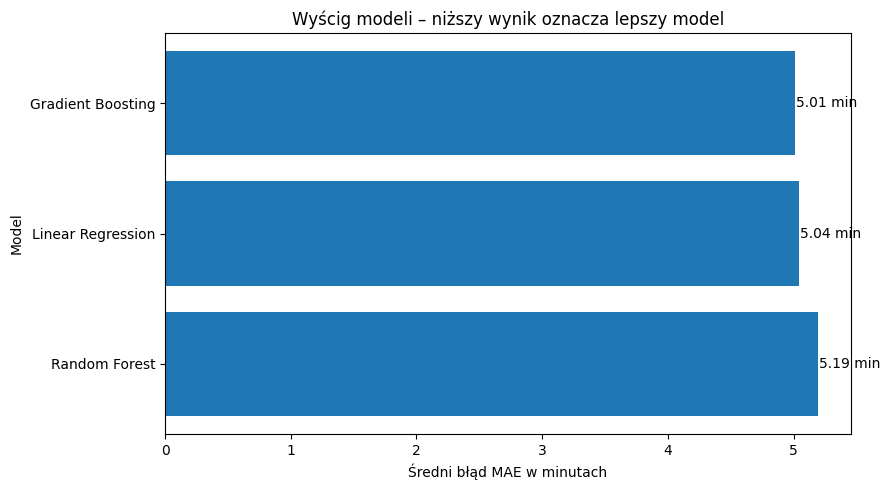

In [71]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.barh(
    model_results["model"],
    model_results["MAE_minutes"]
)

plt.xlabel("Średni błąd MAE w minutach")
plt.ylabel("Model")
plt.title("Wyścig modeli – niższy wynik oznacza lepszy model")
plt.gca().invert_yaxis()

for bar, value in zip(bars, model_results["MAE_minutes"]):
    plt.text(
        value + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f} min",
        va="center"
    )

plt.tight_layout()
plt.show()

In [72]:
race_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE (min)": [
        mae / 60,
        mae_rf / 60,
        mae_gb / 60
    ],
    "RMSE (min)": [
        rmse / 60,
        rmse_rf / 60,
        rmse_gb / 60
    ],
    "R²": [
        r2,
        r2_rf,
        r2_gb
    ]
})

race_results = race_results.sort_values(
    by="MAE (min)"
).reset_index(drop=True)

race_results

,Model,MAE (min),RMSE (min),R²
0,Gradient Boosting,5.012350,6.922823,0.882411
1,Linear Regression,5.044157,6.951133,0.881447
2,Random Forest,5.194045,7.205899,0.872598


In [74]:
from IPython.display import display, HTML

best_style = (
    "background-color: #198754;"
    "color: white;"
    "font-weight: bold;"
)

styled_race = (
    race_results.style
    .format({
        "MAE (min)": "{:.2f}",
        "RMSE (min)": "{:.2f}",
        "R²": "{:.4f}"
    })
    .highlight_min(
        subset=["MAE (min)", "RMSE (min)"],
        props=best_style
    )
    .highlight_max(
        subset=["R²"],
        props=best_style
    )
    .set_caption(
        "Wyścig modeli — zielony kolor oznacza najlepszy wynik"
    )
)

display(HTML(styled_race.to_html()))

,Model,MAE (min),RMSE (min),R²
0,Gradient Boosting,5.01,6.92,0.8824
1,Linear Regression,5.04,6.95,0.8814
2,Random Forest,5.19,7.21,0.8726


## 5. Trenowanie modelu końcowego i zapis

In [75]:
# Trenowanie finalnego modelu Gradient Boosting na pełnym zbiorze danych
# nowy, czysty egzemplarz modelu z takimi samymi hiperparametrami, ale bez wytrenowanych wag.

from sklearn.base import clone
final_model = clone(gradient_boosting_model)
final_model.fit(X, y)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('gender_encoder',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore'),
                                                  ['gender'])])),
                ('regressor',
                 GradientBoostingRegressor(learning_rate=0.05, n_estimators=200,
                                           random_state=42))])

In [76]:
from pathlib import Path
import joblib

# zapisanie wytrenowanego modelu do pliku joblib (lepiej niż pickle)

models_directory = Path("models")
models_directory.mkdir(exist_ok=True)

model_path = models_directory / "halfmarathon_gradient_boosting_v1.joblib"

joblib.dump(final_model, model_path)

print(f"Model zapisano w: {model_path.resolve()}")

Model zapisano w: E:\projekty\DataScientist - Kurs\modul_9\zadanie\models\halfmarathon_gradient_boosting_v1.joblib


In [79]:
# Funkcja konwertująca czas w sekundach na format HH:MM:SS
def seconds_to_time(seconds):
    seconds = int(round(seconds))

    hours = seconds // 3600
    minutes = (seconds % 3600) // 60
    remaining_seconds = seconds % 60

    return f"{hours:02d}:{minutes:02d}:{remaining_seconds:02d}"

In [81]:
# Wczytanie wytrenowanego modelu z pliku joblib i dokonanie predykcji na przykładzie danych

loaded_model = joblib.load(model_path)

example_runner = pd.DataFrame({
    "gender": ["M"],
    "age": [47],
    "time_5k_seconds": [1750]
})

prediction = loaded_model.predict(example_runner)[0]

print(f"Przewidywany czas półmaratonu: {seconds_to_time(prediction)}")

Przewidywany czas półmaratonu: 02:09:05


## 6. Wysłanie modelu do DigitalOcean Spaces

In [82]:
file_name = "models/halfmarathon_gradient_boosting_v1.joblib"

s3.upload_file(
    str(model_path),
    BUCKET,
    file_name
)

print(f"Model przesłano do s3://{BUCKET}/{file_name}")

Model przesłano do s3://moj-halfmarathon-data/models/halfmarathon_gradient_boosting_v1.joblib


In [84]:
file_name = "models/halfmarathon_gradient_boosting_v1.joblib"

model_info = s3.head_object(Bucket=BUCKET, Key=file_name)
print("Rozmiar modelu:", model_info["ContentLength"], "bajtów")
print("Model istnieje w DigitalOcean Spaces.")

Rozmiar modelu: 367042 bajtów
Model istnieje w DigitalOcean Spaces.
